# Trend-Cycle Decomposition of US GDP

*The UC model ladder: from the HP filter to a Bayesian UC model with COVID variance scales*

One engine, `UCTrendCycle`, estimates the whole family

$$
\begin{aligned}
y_t &= \tau_t + c_t \\
\tau_t &= \tau_{t-1} + g_{t-1} + \eta_t, & \eta_t &\sim \mathcal{N}(0,\ \lambda_{\eta,t}\sigma_\eta^2) \\
g_t &= \rho_g g_{t-1} + (1-\rho_g)\bar g + \zeta_t, & \zeta_t &\sim \mathcal{N}(0,\ \lambda_{\zeta,t}\sigma_\zeta^2) \\
c_t &= \phi_1 c_{t-1} + \phi_2 c_{t-2} + \varepsilon_t, & \varepsilon_t &\sim \mathcal{N}(0,\ \lambda_{c,t}\sigma_c^2)
\end{aligned}
$$

with trend $\tau_t$ (log potential output), potential growth $g_t$, output gap $c_t$, and COVID variance-scale paths $\lambda_{i,t}$ (equal to one until rung 4). This tutorial climbs the ladder on US real GDP and confronts every rung with two external benchmarks: **NBER recession dates** (shaded) and the **CBO output gap** ($100 \times [\log \text{GDPC1} - \log \text{GDPPOT}]$).

| Rung | Model | Estimation | Key assumption relaxed |
|---|---|---|---|
| 1 | HP filter | closed form | none: it *is* a UC model with fixed $\sigma_c^2/\sigma_\zeta^2 = 1600$ |
| 2 | Clark UC | maximum likelihood | variance ratio estimated, AR(2) cycle |
| 3 | Bayesian UC | Gibbs | calibrated priors cure the MLE pile-up; full posteriors |
| 4 | + COVID scales | Gibbs + griddy | 2020 loads on volatility, not on the trend |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

from MacroPy import UCTrendCycle, hp_filter, compare_uc
from MacroPy.get_macrodata import get_fred_data
from MacroPy.plots_uc import plot_uc_decomposition, plot_covid_scales, plot_gap_comparison

# Data via the MacroPy FRED API (needs FRED_KEY in a .env file)
# falls back to the packaged CSV without a key or a connection.
load_dotenv()
try:
    key = os.environ["FRED_KEY"]
    us = get_fred_data(["GDPC1", "GDPPOT"], ["gdp", "potential"], "q", key,
                       start_period="1947-01").set_index("date")
    usrec = get_fred_data(["USREC"], ["recession"], "m", key,
                          start_period="1947-01").set_index("date")["recession"]
    us.index += pd.DateOffset(months=2)     # quarter-start -> quarter-end month
    y = 100 * np.log(us["gdp"].dropna());  y.name = "y"
    cbo_gap = (100 * (np.log(us["gdp"]) - np.log(us["potential"]))).dropna()
    cbo_gap = cbo_gap[cbo_gap.index <= y.index[-1]]
    in_rec = usrec.astype(bool)
    edges = in_rec.astype(int).diff()
    starts = list(usrec.index[edges == 1]); ends = list(usrec.index[edges == -1])
    if in_rec.iloc[0]: starts = [usrec.index[0]] + starts
    if len(ends) < len(starts): ends.append(usrec.index[-1])
    nber = list(zip(starts, ends))
    print(f"FRED: GDP {y.index[0].date()} to {y.index[-1].date()} ({len(y)} quarters), "
          f"{len(nber)} NBER recessions, CBO gap from {cbo_gap.index[0].date()}")
except Exception as err:
    data = pd.read_csv("../datasets/USGDP_Data.csv", parse_dates=["date"], index_col="date")
    y = 100 * np.log(data["gdp"]); y.name = "y"
    cbo_gap, nber = None, []
    print(f"FRED unavailable ({type(err).__name__}); using the packaged CSV "
          f"(no CBO/NBER overlays). Sample to {y.index[-1].date()}.")

FRED: GDP 1947-03-01 to 2026-06-01 (318 quarters), 12 NBER recessions, CBO gap from 1949-03-01


## 1. From filter to estimated model

The HP trend solves $\min_\tau \sum(y_t-\tau_t)^2 + 1600\sum(\Delta^2\tau_t)^2$; Harvey and Jaeger (1993) showed it is the smoothed state of the UC model above with $\rho_g=1$, no level noise, a white-noise cycle and $\sigma_c^2/\sigma_\zeta^2 = 1600$ *imposed*. The preset `UCTrendCycle.hp` builds that state-space model and reproduces the filter to numerical precision, which is the rung's lesson: every filter hides a model, so the assumptions might as well be estimated.

Clark (1987) does exactly that by maximum likelihood (rung 2): random-walk drift, AR(2) cycle, free variances. On US data the MLE runs into the classic **pile-up problem** (Stock and Watson, 1998): one of the trend variances collapses to (numerically) zero, or the flat likelihood ridge flips to the mirror mode with a volatile trend and a tiny cycle; near-identical likelihoods decide which, so the cycle/trend split is fragile. That fragility motivates priors.

In [2]:
hp_model = UCTrendCycle.hp(y, lam=1600)
hp_model.fit_mle()
print("max |HP filter - state-space smoother| =",
      f"{np.abs(hp_model.mle_['trend'] - hp_filter(y, 1600)['trend'].to_numpy()).max():.1e}")

clark = UCTrendCycle.clark(y)
fit = clark.fit_mle()
print("Clark MLE:", {k: round(v, 4) for k, v in fit["params"].items()})

max |HP filter - state-space smoother| = 3.7e-06


Clark MLE: {'phi1': 1.457, 'phi2': -0.5546, 'sig2_c': 0.224, 'sig2_eta': 0.8657, 'sig2_zeta': 0.0003}


## 2. Bayesian UC, without and with COVID scales

Two additions (both defaults of `UCTrendCycle`): a mean-reverting drift $\rho_g < 1$, and **calibrated priors** computed from pre-COVID data moments, $\mathrm{sd}(\zeta) = 0.35 \times \mathrm{sd}(\text{13q MA of }\Delta y)$ and $\mathrm{sd}(\eta) = 0.10 \times \mathrm{sd}(\zeta)$ (about 0.12 and 0.012 here, versus generic defaults of 0.5 and 0.05: an order of magnitude tighter, keeping the trend from chasing the data).

Rung 4 keeps the model homoskedastic *except* around the pandemic: each shock gets a Lenza-Primiceri scale path ($\lambda_1, \lambda_2$ free in 2020Q1-Q2, the first two pandemic quarters, then the geometric tail $1+(\lambda_3-1)\rho^{t-t_0-2}$ covering the rebound from 2020Q3 on), sampled by griddy Gibbs. States are drawn jointly by the precision-based simulation smoother (Chan, 2018); an independent Kalman filter cross-checks the likelihood at ~1e-8 and supplies the per-period terms WAIC needs.

In [3]:
kw = dict(drift="ar1", post_draws=10000, burnin=0.5, seed=1)
uc = UCTrendCycle(y, **kw)
uc_covid = UCTrendCycle(y, covid_t0="2020Q1", **kw)
uc.sample_posterior()
uc_covid.sample_posterior()
uc_covid.model_summary()

Sampling Posterior: 100%|██████████| 10000/10000 [00:15<00:00, 655.93it/s]



**MacroPy: A Toolbox for Bayesian Macroeconometric Analysis in Python**
Developed by [Renato Vassallo](https://www.linkedin.com/in/renatovassallo) - Institute for Economic Analysis (IAE-CSIC)
Version 0.2.0

---

**Model Specifications**
- **Model Type**: Unobserved-Components Trend-Cycle (Grant & Chan, 2017)
- **Observed Series**: y
- **Trend Drift**: AR(1) around mean growth (mean-reverting)
- **Trend-Level Shock**: Included
- **Cycle**: AR(2)
- **Sample Period**: 1947-03-01 to 2026-06-01 (318 observations)

---

**Bayesian Estimation Settings**
- **Posterior Simulation**: Gibbs Sampling (precision-based simulation smoother)
- **Prior Calibration Rules**: On (data-relative kappa rules)
- **Total Draws**: 10000
- **Burn-in**: 5000 (50%)
- **COVID Treatment**: Lenza-Primiceri variance scales from 2020-03-01 on (cycle, trend_level, trend_growth; 3 free scales, griddy Gibbs)
- **Random Seed**: 1

---

**Model Equations**

$$

\begin{align*}
y_t &= \tau_t + c_t \\
\tau_t &= \tau_{t-1} + g_{t-1} + \eta_t, & \eta_t &\sim \mathcal{N}(0,\, \lambda_{\eta,t}\sigma_\eta^2) \\
g_t &= \rho_g g_{t-1} + (1-\rho_g)\bar{g} + \zeta_t, & \zeta_t &\sim \mathcal{N}(0,\, \lambda_{\zeta,t}\sigma_\zeta^2) \\
c_t &= \phi_1 c_{t-1} + \phi_2 c_{t-2} + \varepsilon_t,
& \varepsilon_t &\sim \mathcal{N}(0,\, \lambda_{c,t}\sigma_c^2)
\end{align*}

$$


## 3. Four gaps, one dataset

The chart overlays the four estimated output gaps with the CBO gap (dashed) and NBER recessions (shaded). Three things to look for:

1. **Every gap turns down in every shaded band**: the models recover the NBER chronology they never saw.
2. **The HP gap is the odd one out**: white-noise cycle and fixed smoothing make it noisier and shallower, and its 2020 trough is muted because part of the collapse leaks into the trend.
3. **The Bayesian UC gaps track the CBO gap remarkably closely** through 2019, from first principles: no production function, no demographic inputs. Where they disagree (the size of the 2020 trough, the post-2021 overheating) is exactly where the priors about trend flexibility matter.

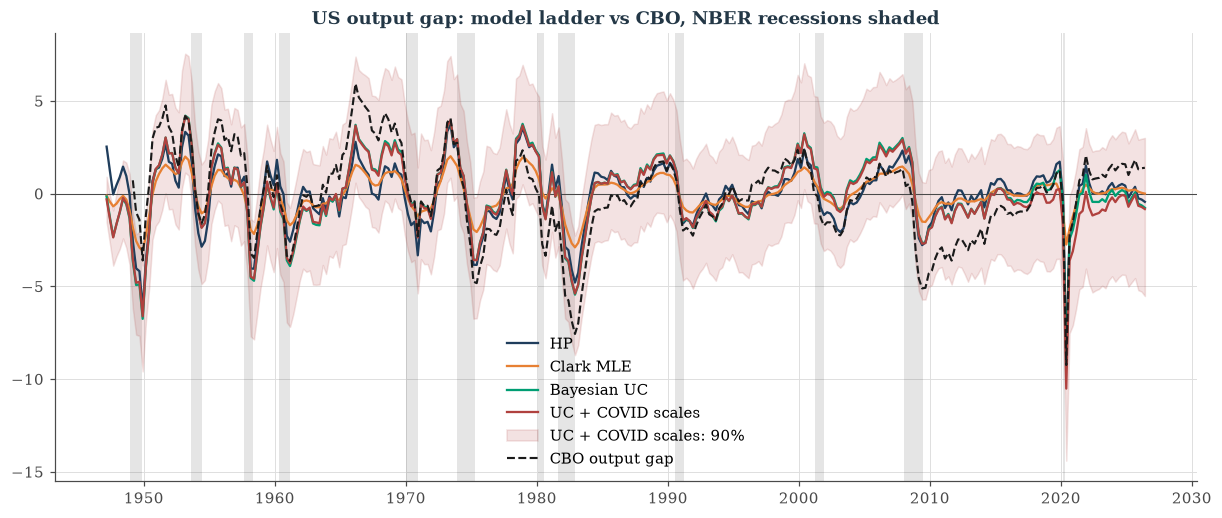

In [4]:
fig, ax = plot_gap_comparison(
    {"HP": hp_model, "Clark MLE": clark,
     "Bayesian UC": uc, "UC + COVID scales": uc_covid},
    cred=0.90, shade=nber,
    extra_series={"CBO output gap": cbo_gap} if cbo_gap is not None else None,
    title="US output gap: model ladder vs CBO, NBER recessions shaded")
fig.set_size_inches(11, 4.6)

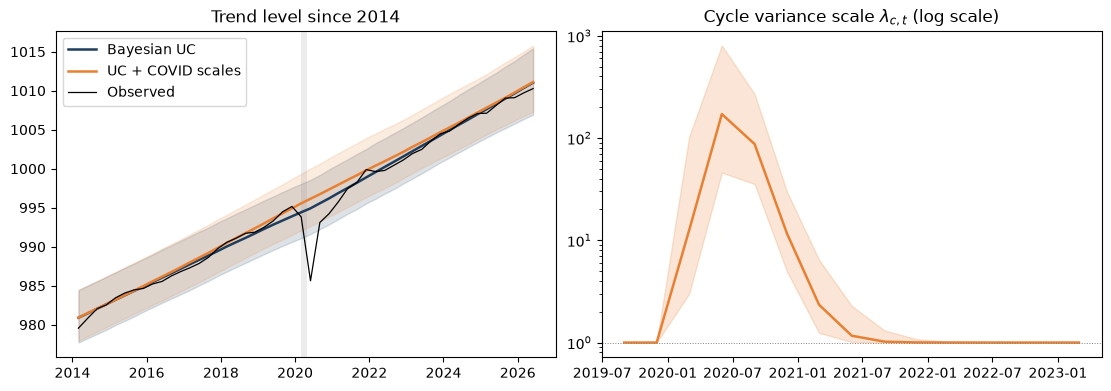

Posterior median (lambda1, lambda2, lambda3, rho): [1.2480e+01 1.7151e+02 8.7310e+01 1.2000e-01]


In [5]:
# The pandemic in close-up: trend level and COVID variance scales
zoom = y.index >= "2014-01-01"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for m, col, lab in ((uc, "#1F3D5C", "Bayesian UC"),
                    (uc_covid, "#E78033", "UC + COVID scales")):
    fr = m.decomposition_frame(cred=0.9)[zoom]
    axes[0].plot(fr.index, fr["trend"], color=col, lw=1.8, label=lab)
    axes[0].fill_between(fr.index, fr["trend_lower"], fr["trend_upper"],
                         color=col, alpha=0.15)
axes[0].plot(y.index[zoom], y[zoom], "k", lw=0.9, label="Observed")
for s0, s1 in nber:
    if s1 >= pd.Timestamp("2014-01-01"):
        axes[0].axvspan(max(s0, pd.Timestamp("2014-01-01")), s1,
                        color="gray", alpha=0.15, lw=0)
axes[0].set_title("Trend level since 2014"); axes[0].legend()

lam = uc_covid.draws["lambda_cycle"]
t0 = uc_covid.covid_t0
sl = slice(t0 - 2, t0 + 13)
axes[1].plot(y.index[sl], np.median(lam, 0)[sl], color="#E78033", lw=1.8)
axes[1].fill_between(y.index[sl], np.percentile(lam, 16, 0)[sl],
                     np.percentile(lam, 84, 0)[sl], color="#E78033", alpha=0.2)
axes[1].set_yscale("log"); axes[1].axhline(1, color="gray", lw=0.7, ls=":")
axes[1].set_title(r"Cycle variance scale $\lambda_{c,t}$ (log scale)")
plt.show()
print("Posterior median (lambda1, lambda2, lambda3, rho):",
      np.median(uc_covid.draws["cov_cycle"], 0).round(2))

Without the scales, the homoskedastic model inflates $\sigma_c^2$ *for the whole sample* to accommodate three pandemic quarters, and its trend dips mechanically in 2020. With them, the pandemic is read as a huge transitory cycle shock (scale in the hundreds, decaying within a year) and the trend sails through: the two trends differ visibly during 2020-2021 and reconverge after. WAIC, computed from the one-step-ahead predictive decomposition and therefore comparable across the two specifications, is unambiguous about which reading the data prefer:

In [6]:
compare_uc({"Bayesian UC": uc, "UC + COVID scales": uc_covid})

,waic,pwaic,elpd_waic,lppd,dic,pD,best_waic
model,,,,,,,
Bayesian UC,995.78,25.61,-497.89,-472.28,969.62,4.38,
UC + COVID scales,825.54,6.46,-412.77,-406.31,822.54,3.90,*


## 4. Wrap-up

The ladder's moral: the HP filter, Clark's model and the Bayesian UC are the *same model* under progressively weaker restrictions, and on US data each relaxation earns its keep: estimated dynamics recover the NBER chronology, calibrated priors reproduce the CBO gap without CBO's supply-side machinery, and the COVID scales let 2020 be what it was, a gigantic transitory shock rather than a collapse of potential.

Extensions that slot into the same engine: stochastic volatility in the UC shocks (Grant and Chan, 2017), correlated trend-cycle innovations, and UC-SV for inflation (Stock and Watson, 2007). For conditional forecasting with this class (restrictions on future annual growth, in the spirit of Waggoner and Zha, 1999), see `UCTrendCycle.conditional_forecast`.

## References

- Clark, P.K. (1987). The cyclical component of U.S. economic activity. *Quarterly Journal of Economics* 102(4), 797-814.
- Harvey, A.C. and Jaeger, A. (1993). Detrending, stylized facts and the business cycle. *Journal of Applied Econometrics* 8(3), 231-247.
- Stock, J.H. and Watson, M.W. (1998). Median unbiased estimation of coefficient variance in a time-varying parameter model. *Journal of the American Statistical Association* 93(441), 349-358.
- Grant, A.L. and Chan, J.C.C. (2017). Reconciling output gaps: unobserved components model and Hodrick-Prescott filter. *Journal of Economic Dynamics and Control* 75, 114-121.
- Stock, J.H. and Watson, M.W. (2007). Why has U.S. inflation become harder to forecast? *Journal of Money, Credit and Banking* 39(s1), 3-33.
- Waggoner, D.F. and Zha, T. (1999). Conditional forecasts in dynamic multivariate models. *Review of Economics and Statistics* 81(4), 639-651.
- Lenza, M. and Primiceri, G.E. (2022). How to estimate a vector autoregression after March 2020. *Journal of Applied Econometrics* 37(4), 688-699.